# 01 – Exploring the Trial-Radar training table

Exploration only; nothing in `src/` or `app/` imports from this notebook.
It reads `data/processed/trials.parquet` (made by `src/build_dataset.py`): every interventional trial on
ClinicalTrials.gov that started 2008-2019 and either completed (`label = 0`) or was terminated (`label = 1`).
Only design-time columns are used here, in line with the leakage rules in `CLAUDE.md`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Works whether Jupyter starts in notebooks/ or in the repo root.
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
df = pd.read_parquet(ROOT / "data" / "processed" / "trials.parquet")
BASE = df["label"].mean()  # overall terminated rate, drawn as a reference line

INK, ACCENT, GREY = "#1f1f1f", "#c8442b", "#b9b9b9"
plt.rcParams.update({
    "figure.dpi": 80, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK, "axes.labelcolor": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})
print(f"{len(df):,} trials, {df.shape[1]} columns, terminated rate {BASE:.1%}")

162,457 trials, 38 columns, terminated rate 11.3%


## 1. Status counts

,trials,share
overall_status,,
COMPLETED,144107,0.887
TERMINATED,18350,0.113


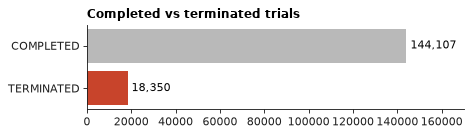

In [2]:
counts = df["overall_status"].value_counts()
table = pd.DataFrame({"trials": counts, "share": (counts / counts.sum()).round(3)})
display(table)

fig, ax = plt.subplots(figsize=(6, 1.8))
ax.barh(counts.index[::-1], counts.values[::-1], color=[ACCENT, GREY])
for i, v in enumerate(counts.values[::-1]):
    ax.text(v, i, f" {v:,}", va="center")
ax.set_xlim(0, counts.max() * 1.18)
ax.set_title("Completed vs terminated trials")
plt.tight_layout()
plt.show()

**Takeaway.** 144,107 trials completed and 18,350 were terminated, so 11.3% are terminated. A model that always
answers "completed" would be right 88.7% of the time, which is why we report ROC-AUC and PR-AUC instead of accuracy.
Withdrawn and still-running trials were already removed by `build_dataset.py`, so they do not appear here.

In [3]:
def rate_chart(col, title, min_n=100, order=None, figsize=(7, 3.2)):
    """Bar chart of the terminated rate per group of `col`, with group sizes and the overall rate as a line."""
    g = df.groupby(col, dropna=True)["label"].agg(n="size", rate="mean")
    g = g[g["n"] >= min_n]  # tiny groups give meaningless percentages
    g = g.loc[order] if order else g.sort_values("rate")
    fig, ax = plt.subplots(figsize=figsize)
    ax.barh(g.index.astype(str), g["rate"] * 100, color=ACCENT)
    ax.axvline(BASE * 100, color=INK, ls="--", lw=1)
    ax.text(BASE * 100, len(g) - 0.4, f" all trials {BASE:.1%}", fontsize=8, va="bottom")
    for i, (rate, n) in enumerate(zip(g["rate"], g["n"])):
        ax.text(rate * 100, i, f" {rate:.1%}  (n={n:,})", va="center", fontsize=8,
                bbox=dict(fc="white", ec="none", pad=0.6))
    ax.set_xlim(0, g["rate"].max() * 100 * 1.45)
    ax.set_xlabel("terminated, % of trials")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()
    return g

## 2. Terminated rate by phase

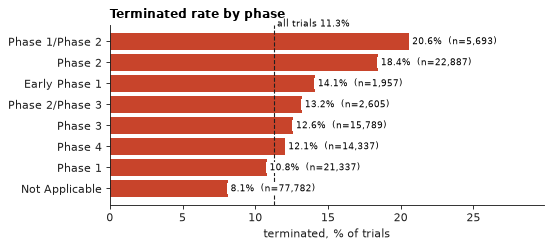

In [4]:
_ = rate_chart("phase_label", "Terminated rate by phase")

**Takeaway.** Phase 1/2 (20.6%) and Phase 2 (18.4%) trials are stopped about twice as often as "Not applicable"
trials (8.1%), which make up almost half of the data. Phase 3 and 4 sit close to the average. The spread is large,
so phase is an obvious feature for the model.

## 3. Terminated rate by sponsor class

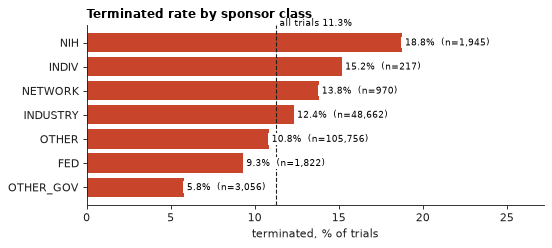

In [5]:
_ = rate_chart("sponsor_class", "Terminated rate by sponsor class")

**Takeaway.** NIH-sponsored trials are terminated most often (18.8%), industry sits slightly above average (12.4%),
and other government agencies (`OTHER_GOV`) are lowest (5.8%). "OTHER" (universities, hospitals and similar) is the biggest group
with 105,756 trials and is close to the average. Groups below 100 trials are hidden because their rates are noise.

## 4. Terminated rate by masking

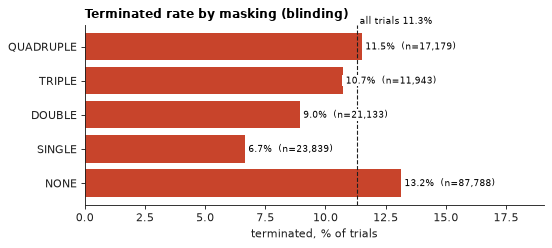

In [6]:
_ = rate_chart("masking", "Terminated rate by masking (blinding)",
               order=["NONE", "SINGLE", "DOUBLE", "TRIPLE", "QUADRUPLE"])

**Takeaway.** Open-label trials (`NONE`) are stopped twice as often as single-blind ones (13.2% vs 6.7%). The
pattern is not a clean ladder: quadruple-masked trials (11.5%) are above single and double. Masking is tied to
phase and design, so this is an association, not proof that blinding protects a trial.

## 5. Terminated rate by allocation

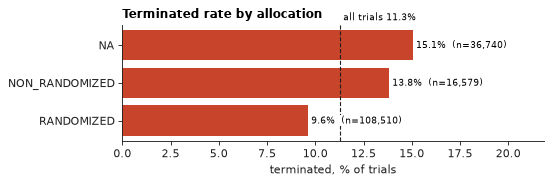

In [7]:
_ = rate_chart("allocation", "Terminated rate by allocation", figsize=(7, 2.4))

**Takeaway.** Randomized trials are terminated least often (9.6%), non-randomized ones more often (13.8%), and
trials with no allocation (`NA`, in practice single-group studies) most often (15.1%). The `NA` group is also large,
36,740 trials, so the difference matters in practice.

## 6. Terminated rate by start year

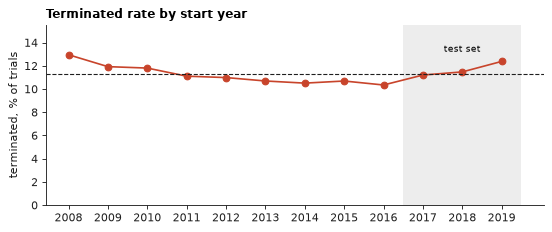

start_date,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019
n,"10,424","11,085","11,472","11,996","12,499","13,002","14,087","14,811","15,224","15,790","16,222","15,845"
rate,13.0%,11.9%,11.8%,11.1%,11.0%,10.7%,10.5%,10.7%,10.3%,11.2%,11.5%,12.4%


In [8]:
by_year = df.groupby(df["start_date"].dt.year)["label"].agg(n="size", rate="mean")
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(by_year.index, by_year["rate"] * 100, marker="o", color=ACCENT)
ax.axvspan(2016.5, 2019.5, color=GREY, alpha=0.25, lw=0)
ax.text(2018, by_year["rate"].max() * 100 * 1.02, "test set", ha="center", fontsize=8)
ax.axhline(BASE * 100, color=INK, ls="--", lw=1)
ax.set_ylim(0, by_year["rate"].max() * 100 * 1.2)
ax.set_xticks(by_year.index)
ax.set_ylabel("terminated, % of trials")
ax.set_title("Terminated rate by start year")
plt.tight_layout()
plt.show()
display(by_year.assign(n=by_year["n"].map("{:,}".format), rate=by_year["rate"].map("{:.1%}".format)).T)

**Takeaway.** The rate fell from 13.0% for 2008 starts to 10.3% for 2016 starts, then rose again to 12.4% for 2019.
The train period (2008-2016) averages 11.1% and the test period (2017-2019) 11.7%, a small shift that is one more
reason to split by start date rather than at random. Only trials that have already ended are in the table, so the
latest start years may be a slightly different mix.

## 7. Missing values

In [9]:
rows = []
for col in df.columns[df.isna().any()]:
    m = df[col].isna()
    rows.append({"column": col, "missing": int(m.sum()), "missing_%": round(m.mean() * 100, 1),
                 "terminated_rate_if_missing": round(df.loc[m, "label"].mean(), 3),
                 "terminated_rate_if_present": round(df.loc[~m, "label"].mean(), 3)})
miss = pd.DataFrame(rows).sort_values("missing", ascending=False).set_index("column")
display(miss)
print(f"{df.isna().any().sum()} of {df.shape[1]} columns have any missing value; nothing is imputed here.")

,missing,missing_%,terminated_rate_if_missing,terminated_rate_if_present
column,,,,
has_dmc,16655,10.3,0.086,0.116
min_age_years,6489,4.0,0.093,0.114
primary_purpose,3728,2.3,0.054,0.114
allocation,628,0.4,0.104,0.113
masking,575,0.4,0.099,0.113
intervention_model,431,0.3,0.153,0.113
healthy_volunteers,148,0.1,0.034,0.113
sex,98,0.1,0.041,0.113
phase_label,70,0.0,0.243,0.113


11 of 38 columns have any missing value; nothing is imputed here.


**Takeaway.** Only 11 of 38 columns have gaps, and the largest is `has_dmc` with 10.3% missing. Trials with a
missing `primary_purpose` (5.4%) or `healthy_volunteers` (3.4%) are terminated less often than average, so
"missing" can carry some signal, but those groups are small (148 and 3,728 trials) and the `phase` gap rests on only 70 trials, so treat
these rates with care.

## 8. Eligibility text length: terminated vs completed

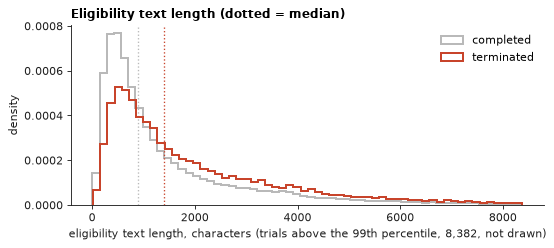

,count,mean,std,min,25%,50%,75%,max
overall_status,,,,,,,,
COMPLETED,144101,1527,1681,5,479,893,1918,19573
TERMINATED,18349,2096,2004,18,712,1392,2840,18153


In [10]:
cap = df["eligibility_text_len"].quantile(0.99)  # the long tail would squash the plot, so it is left out of the chart
fig, ax = plt.subplots(figsize=(7, 3.2))
for lab, name, colour in [(0, "completed", GREY), (1, "terminated", ACCENT)]:
    s = df.loc[df["label"] == lab, "eligibility_text_len"].dropna().astype(float)
    ax.hist(s[s <= cap], bins=60, density=True, histtype="step", lw=1.8, color=colour, label=name)
    ax.axvline(s.median(), color=colour, ls=":", lw=1.2)
ax.set_xlabel(f"eligibility text length, characters (trials above the 99th percentile, {cap:,.0f}, not drawn)")
ax.set_ylabel("density")
ax.set_title("Eligibility text length (dotted = median)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()
display(df.groupby("overall_status")["eligibility_text_len"].describe().round(0).astype(int))

**Takeaway.** Terminated trials have longer eligibility criteria: median 1,392 characters against 893 for
completed ones. Long criteria often mean more conditions a participant must meet, which makes recruiting harder,
though that explanation is our guess and the data only shows the link. The text length is known at registration
and is one of the 29 model features.